# Taller Olist · Módulo 0 — Datos, calidad y EDA

**Curso:** SI7009 Aprendizaje Automático · Maestría en Ciencia de Datos y Analítica · EAFIT 2026-2

Este notebook valida la base `olist.duckdb` y deja listas las decisiones de calidad que usa el
**Módulo A (clasificación de entregas tardías)**. Responde cinco preguntas:

1. **Granularidad y llaves.** ¿Qué identifica a cada fila y qué tablas multiplican filas al unirse?
2. **Calidad.** ¿Qué datos faltan, cuáles son inconsistentes y cómo se tratan?
3. **Identidad del cliente.** ¿En qué se diferencian `customer_id` y `customer_unique_id`?
4. **Cobertura temporal.** ¿Qué rango de fechas es útil?
5. **EDA orientado al Módulo A.** Tiempos de entrega, retraso, demanda, geografía y clientes.

**Cómo está organizado (y cómo se llegó a la limpieza)**

| Paso | Secciones | Archivos SQL | Qué se hace |
|---|---|---|---|
| 1. Diagnóstico | 1 a 4 | `00_01` a `00_17` | Se revisan los datos **crudos**. Cada hallazgo termina en una **Decisión** que indica qué archivo de limpieza la implementa. |
| 2. Limpieza | 5 | `00_20` a `00_28` | A partir de esas decisiones se escribieron los SQL de limpieza. Aquí se muestra cada uno, se ejecuta y se **verifica** que corrige lo que encontró el diagnóstico. |
| 3. EDA | 6 | `00_30` a `00_38` | Se analizan los datos **ya limpios** para orientar el modelado del Módulo A. |
| 4. Entrega al Módulo A | 7 | — | Qué tablas limpias recibe el Módulo A y cómo las recrea. |

**Reglas del taller que se cumplen aquí**

- Toda lectura de datos es con SQL sobre `olist.duckdb`, en modo **solo lectura**. No se lee ningún CSV.
- Las consultas viven en la carpeta `sql/` y el notebook las lee desde allí.
- Cruces, filtros y agregaciones se resuelven en SQL; pandas solo recibe el resultado.
- Las fechas de corte se pasan como parámetro `?`, nunca escritas dentro de la consulta.
- Las tablas intermedias son `TEMP TABLE` (viven en memoria y no modifican la base).

## 0. Configuración

In [1]:
# Librerías
import subprocess
import sys
from pathlib import Path

import duckdb
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd
from IPython.display import display

# ---------------------------------------------------------------------------
# Rutas relativas a la raíz del repositorio.
# Si el notebook se ejecuta desde notebooks/, la raíz es la carpeta padre.
# ---------------------------------------------------------------------------
RAIZ = Path.cwd() if (Path.cwd() / "sql").exists() else Path.cwd().parent
RUTA_SQL = RAIZ / "sql"
RUTA_DB = RAIZ / "data" / "olist.duckdb"
RUTA_SCRIPT = RAIZ / "scripts" / "build_olist_duckdb.py"

# ---------------------------------------------------------------------------
# Parámetros del análisis (se pasan a las consultas como ?)
# ---------------------------------------------------------------------------
SEED = 42

# Período útil del dataset (justificado en la sección 4). El fin es excluyente.
PERIODO_INICIO = "2017-01-01"
PERIODO_FIN = "2018-08-22"

# Partición temporal fija del Módulo A (por fecha de compra). Los fines son excluyentes.
INICIO_TRAIN = "2017-01-01"
INICIO_VAL = "2018-04-01"
INICIO_TEST = "2018-06-01"
FIN_TEST = "2018-08-16"   # la prueba incluye hasta el 15 de agosto de 2018

# Rango completo de fechas de compra, para ver la cobertura total del dataset
RANGO_COMPLETO = ("2016-09-01", "2018-10-18")

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

print(f"Raíz del proyecto : {RAIZ}")
print(f"Base de datos     : {RUTA_DB}")
print(f"DuckDB {duckdb.__version__} · pandas {pd.__version__}")

Raíz del proyecto : /tmp/claude-0/-home-claude/8313014f-d9d7-5674-bd85-3a9acf337149/scratchpad/taller
Base de datos     : /tmp/claude-0/-home-claude/8313014f-d9d7-5674-bd85-3a9acf337149/scratchpad/taller/data/olist.duckdb
DuckDB 2.0.0 · pandas 3.0.6


In [2]:
# ---------------------------------------------------------------------------
# Estilo de los gráficos: marcas delgadas, ejes y grilla discretos
# ---------------------------------------------------------------------------
AZUL = "#2a78d6"      # serie principal
NARANJA = "#eb6834"   # resaltado: órdenes tardías
GRIS = "#8a8984"      # referencias y anotaciones
TINTA = "#333333"
TINTA_2 = "#656565"
GRILLA = "#e4e4e2"
FONDOS_PARTICION = {"Entrenamiento": "#f3f3f1", "Validación": "#e6e6e3", "Prueba": "#d9d9d5"}

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.figsize": (10, 4),
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.edgecolor": TINTA_2,
    "axes.labelcolor": TINTA,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRILLA,
    "grid.linewidth": 0.7,
    "xtick.color": TINTA_2,
    "ytick.color": TINTA_2,
    "text.color": TINTA,
    "legend.frameon": False,
    "lines.linewidth": 1.6,
})

### Funciones del notebook

- `conectar()` abre `olist.duckdb` en solo lectura. Si la base no existe, la construye con el script del curso.
- `leer_sql()` devuelve el texto de un archivo de `sql/`.
- `consulta()` ejecuta un `.sql` que devuelve filas y entrega un `DataFrame`.
- `ejecutar()` ejecuta un `.sql` que crea una tabla temporal (no devuelve filas).
- `mostrar_sql()` imprime el contenido de un `.sql`, para leer la consulta dentro del notebook.
- `formato_miles()` y `sombrear_particiones()` son ayudas de los gráficos.

In [3]:
def conectar(ruta_db: Path = RUTA_DB) -> duckdb.DuckDBPyConnection:
    """Abre la base en modo solo lectura. Si no existe, la construye con el script del curso."""
    if not ruta_db.exists():
        print("No se encontró olist.duckdb: se construye con el script del curso…")
        subprocess.run(
            [sys.executable, str(RUTA_SCRIPT), "--out", str(ruta_db)],
            check=True,
        )
    return duckdb.connect(str(ruta_db), read_only=True)


def leer_sql(nombre: str) -> str:
    """Lee el archivo sql/<nombre>.sql y devuelve su texto."""
    return (RUTA_SQL / f"{nombre}.sql").read_text(encoding="utf-8")


def consulta(nombre: str, params: list | None = None) -> pd.DataFrame:
    """Ejecuta una consulta de sql/ (con parámetros ? opcionales) y devuelve un DataFrame."""
    return con.execute(leer_sql(nombre), params or []).df()


def ejecutar(nombre: str, params: list | None = None) -> None:
    """Ejecuta un .sql que crea una tabla temporal (CREATE TEMP TABLE …)."""
    con.execute(leer_sql(nombre), params or [])
    print(f"✔ {nombre}")


def mostrar_sql(nombre: str) -> None:
    """Imprime el contenido de sql/<nombre>.sql."""
    print(f"── sql/{nombre}.sql " + "─" * 40)
    print(leer_sql(nombre))


def formato_miles(ax, eje: str = "y") -> None:
    """Muestra los números del eje con separador de miles."""
    formato = mticker.FuncFormatter(lambda v, _: f"{v:,.0f}")
    (ax.yaxis if eje == "y" else ax.xaxis).set_major_formatter(formato)


def sombrear_particiones(ax) -> None:
    """Sombrea en el eje temporal las particiones fijas del Módulo A."""
    tramos = [
        ("Entrenamiento", INICIO_TRAIN, INICIO_VAL),
        ("Validación", INICIO_VAL, INICIO_TEST),
        ("Prueba", INICIO_TEST, FIN_TEST),
    ]
    for nombre, ini, fin in tramos:
        ini, fin = pd.Timestamp(ini), pd.Timestamp(fin)
        ax.axvspan(ini, fin, color=FONDOS_PARTICION[nombre], zorder=0)
        ax.text(ini + (fin - ini) / 2, 1.0, nombre, transform=ax.get_xaxis_transform(),
                ha="center", va="bottom", fontsize=9, color=TINTA_2)

In [4]:
con = conectar()

# Verificación: los conteos deben coincidir con el enunciado del taller (sección 2.3)
FILAS_ESPERADAS = {
    "orders": 99_441, "order_items": 112_650, "order_payments": 103_886,
    "order_reviews": 99_224, "customers": 99_441, "sellers": 3_095,
    "products": 32_951, "geolocation": 1_000_163, "category_translation": 71,
}
conteo = consulta("00_01_conteo_tablas")
conteo["esperadas"] = conteo["tabla"].map(FILAS_ESPERADAS)
conteo["coincide"] = conteo["filas"] == conteo["esperadas"]
display(conteo)
assert conteo["coincide"].all(), "La base no coincide con el enunciado: reconstrúyala."

,tabla,filas,esperadas,coincide
0,orders,99441,99441,True
1,order_items,112650,112650,True
2,order_payments,103886,103886,True
3,order_reviews,99224,99224,True
4,customers,99441,99441,True
5,sellers,3095,3095,True
6,products,32951,32951,True
7,geolocation,1000163,1000163,True
8,category_translation,71,71,True


## 1. Granularidad y llaves

### 1.1 Unicidad de las llaves

In [5]:
llaves = consulta("00_02_unicidad_llaves")
display(llaves)

,tabla,llave,filas,distintos,filas_repetidas,es_unica
0,orders,order_id,99441,99441,0,True
1,customers,customer_id,99441,99441,0,True
2,customers,customer_unique_id,99441,96096,3345,False
3,sellers,seller_id,3095,3095,0,True
4,products,product_id,32951,32951,0,True
5,order_items,"(order_id, order_item_id)",112650,112650,0,True
6,order_payments,"(order_id, payment_sequential)",103886,103886,0,True
7,order_reviews,review_id,99224,98410,814,False
8,order_reviews,"(review_id, order_id)",99224,99224,0,True
9,geolocation,geolocation_zip_code_prefix,1000163,19015,981148,False


**Lectura**

- `orders`, `customers` (`customer_id`), `sellers`, `products`, `order_items` y `order_payments` tienen
  llaves únicas. En `order_items` la llave es compuesta: `(order_id, order_item_id)`. En `order_payments`
  también: `(order_id, payment_sequential)`.
- **`order_reviews.review_id` no es única**: hay `review_id` que aparecen en varias órdenes. La llave
  real es `(review_id, order_id)`.
- `customer_unique_id` se repite: es la persona, no la orden (sección 3).
- `geolocation` **no tiene llave**: cada prefijo postal tiene muchas filas (coordenadas de distintas
  direcciones). Hay que agregarla antes de cruzarla (sección 5).

### 1.2 Cardinalidad de las relaciones

In [6]:
cardinalidad = consulta("00_03_cardinalidad_relaciones")
cardinalidad["pct_con_varios"] = (100 * cardinalidad["padres_con_varios_hijos"] / cardinalidad["padres"]).round(2)
display(cardinalidad)

,relacion,padre,padres,prom_hijos,max_hijos,padres_con_varios_hijos,pct_con_varios
0,orders → customers (customer_id),orden,99441,1.000,1,0.0,0.00
1,orders → order_items,orden,98666,1.142,21,9803.0,9.94
2,orders → order_payments,orden,99440,1.045,29,2961.0,2.98
3,orders → order_reviews,orden,98673,1.006,3,547.0,0.55
4,orders → sellers (vía order_items),orden,98666,1.014,5,1278.0,1.30
5,customer_unique_id → orders,cliente real,96096,1.035,17,2997.0,3.12
6,prefijo postal → geolocation,prefijo,19015,52.599,1146,17972.0,94.51


In [7]:
integridad = consulta("00_04_integridad_referencial")
display(integridad)

,chequeo,registros
0,orders sin cliente,0
1,orders sin ítems,775
2,orders sin pagos,1
3,orders sin reseña,768
4,order_items sin producto,0
5,order_items sin vendedor,0
6,order_reviews sin orden,0


**Lectura**

| Relación | Cardinalidad | ¿Multiplica filas al unirse con `orders`? |
|---|---|---|
| `orders` → `customers` | 1:1 por `customer_id` | No |
| `orders` → `order_items` | 1:N (hasta 21 ítems por orden) | **Sí** |
| `orders` → `order_payments` | 1:N (hasta 29 pagos por orden) | **Sí** |
| `orders` → `order_reviews` | 1:N (algunas órdenes tienen 2 o 3 reseñas) | **Sí** |
| `order_items` → `sellers` / `products` | N:1 | No (desde ítems) |
| `customer_unique_id` → `orders` | 1:N | Solo si se agrupa por persona |
| prefijo postal → `geolocation` | 1:N (~53 filas por prefijo) | **Sí, y mucho** |

La integridad referencial es buena: todo ítem tiene producto y vendedor, y toda orden tiene cliente.
Lo que falta son hijos: hay órdenes sin ítems, una orden sin pagos y órdenes sin reseña.

### 1.3 Demostración: el join ingenuo infla los totales

Unir `orders` con `order_items` y `order_payments` en una sola consulta repite cada pago tantas veces
como ítems tenga la orden.

In [8]:
multiplicacion = consulta("00_05_multiplicacion_filas")
display(multiplicacion)

ingenuo, correcto = multiplicacion["suma_pagos"].iloc[0], multiplicacion["suma_pagos"].iloc[1]
print(f"El join ingenuo infla la suma de pagos en {100 * (ingenuo / correcto - 1):.1f} %.")

,metodo,filas,ordenes,suma_pagos
0,Join ingenuo (orders × items × payments),117601,98665,20308134.71
1,Agregar por order_id antes de unir,99441,99441,16008872.12
2,Referencia: suma directa de order_payments,103886,99440,16008872.12


El join ingenuo infla la suma de pagos en 26.9 %.


**Regla que se aplica en todo el taller:** cada tabla 1:N (`order_items`, `order_payments`,
`order_reviews`, `geolocation`) se **agrega primero por su llave de unión** y solo después se cruza.
Así cada orden queda en una sola fila. La segunda fila de la tabla anterior aplica la regla y coincide
con la suma directa de `order_payments`.

## 2. Calidad de los datos

### 2.1 Faltantes en las fechas de la orden

In [9]:
nulos = consulta("00_06_nulos_fechas_por_estado")
display(nulos)

,estado,ordenes,sin_aprobacion,sin_entrega_transportador,sin_entrega_cliente,sin_fecha_estimada
0,delivered,96478,14.0,2.0,8.0,0.0
1,shipped,1107,0.0,0.0,1107.0,0.0
2,canceled,625,141.0,550.0,619.0,0.0
3,unavailable,609,0.0,609.0,609.0,0.0
4,invoiced,314,0.0,314.0,314.0,0.0
5,processing,301,0.0,301.0,301.0,0.0
6,created,5,5.0,5.0,5.0,0.0
7,approved,2,0.0,2.0,2.0,0.0


Los faltantes son **coherentes con el estado** de la orden: una orden `shipped` todavía no tiene
fecha de entrega al cliente y una `canceled` puede no tener ninguna. Lo anómalo está en las órdenes
`delivered`:

- **8 órdenes entregadas sin fecha de entrega al cliente.** No se puede calcular el target y se excluyen del Módulo A.
- **14 órdenes entregadas sin fecha de aprobación.** El modelo A se usa en el momento de la aprobación, así que se excluyen de A.
- 2 órdenes entregadas sin fecha de entrega al transportador. No afectan a A, porque esa fecha no se usa (sería fuga).

➜ **Se implementa en** `00_22_ordenes_marcadas.sql` con las marcas `entregada` y `tiene_aprobacion`,
que definen la población del Módulo A (sección 5.3).

### 2.2 Fechas inconsistentes

In [10]:
fechas = consulta("00_07_fechas_inconsistentes")
display(fechas)

,regla,ordenes
0,aprobacion_antes_de_compra,0.0
1,transportador_antes_de_compra,166.0
2,transportador_antes_de_aprobacion,1359.0
3,entrega_antes_de_compra,0.0
4,entrega_antes_de_aprobacion,61.0
5,entrega_antes_de_transportador,23.0
6,estimada_antes_de_compra,0.0
7,entregada_sin_fecha_de_entrega,8.0
8,fecha_de_entrega_sin_estado_entregada,6.0


**Lectura y decisión**

- No hay entregas antes de la compra ni fechas estimadas antes de la compra.
- **Transportador antes de la aprobación** es frecuente. Es plausible que la aprobación del pago se
  registre tarde (por ejemplo, boleto), así que no se trata como error.
- **Transportador antes de la compra** es imposible, pero esa fecha no se usa en el Módulo A (es
  posterior a la aprobación y sería fuga). Se deja documentada.
- **Entrega al cliente antes de la entrega al transportador** es imposible y afecta directamente al
  target, porque una de las dos fechas está mal. **Estas órdenes se excluyen.**
- **Entrega al cliente antes de la aprobación** también se excluye: la aprobación es el momento en
  que se usa el modelo A, y no tiene sentido predecir el retraso de una orden ya entregada. Indica
  además que la fecha de aprobación de esas órdenes no es confiable.
- Hay órdenes con fecha de entrega cuyo estado no es `delivered` (por ejemplo, canceladas). Quedan
  fuera de la población de A porque se filtra por estado.

➜ **Se implementa en** `00_22_ordenes_marcadas.sql` (marca `fechas_coherentes`) y se filtra en
`00_23_ordenes_validas.sql` (sección 5.3).

### 2.3 Órdenes sin ítems

In [11]:
sin_items = consulta("00_08_ordenes_sin_items")
display(sin_items)
print(f"Total de órdenes sin ítems: {sin_items['ordenes_sin_items'].sum():,}")

,estado,ordenes_sin_items
0,unavailable,603
1,canceled,164
2,created,5
3,invoiced,2
4,shipped,1


Total de órdenes sin ítems: 775


Casi todas son `unavailable` o `canceled`: órdenes que nunca se despacharon. **Se excluyen**, porque
sin ítems no hay producto, vendedor, peso ni flete.

➜ **Se implementa en** `00_22_ordenes_marcadas.sql` (marca `tiene_items`) y se filtra en
`00_23_ordenes_validas.sql` (sección 5.3).

### 2.4 ¿Los pagos cuadran con precio + flete?

In [12]:
pagos = consulta("00_09_pagos_vs_items")
display(pagos)

,resultado,ordenes,pct_ordenes,mediana_diferencia,max_diferencia_abs
0,cuadra,98222,99.550,0.00,0.01
1,pago mayor que ítems,296,0.300,5.46,182.81
2,pago menor que ítems,147,0.149,-2.50,336.93
3,sin pagos,1,0.001,NaN,NaN


Más del 99 % de las órdenes cuadra al centavo. Las diferencias restantes son pequeñas (mediana de
pocos reales) y son compatibles con intereses por cuotas o con vouchers. **Decisión:** el valor de la
orden se toma de `order_items` (precio + flete), que existe para todas las órdenes con ítems. De
`order_payments` solo se usan el medio de pago y las cuotas.

➜ No requiere tabla de limpieza: se aplica al construir las variables del Módulo A.

### 2.5 Prefijos postales sin geolocalización

Este es el hallazgo de calidad más importante para el Módulo A, porque la **distancia
cliente–vendedor** depende de este cruce.

In [13]:
prefijos = consulta("00_10_prefijos_postales")
display(prefijos)

,tabla,registros,prefijos_con_menos_de_5_digitos,sin_geo_cruce_crudo,sin_geo_cruce_corregido
0,customers,99441,23995.0,24265.0,279.0
1,sellers,3095,1027.0,1033.0,8.0


En `customers` y `sellers` casi una cuarta parte de los prefijos tiene **4 dígitos**: al exportar los
CSV se perdió el cero a la izquierda (`'1151'` en vez de `'01151'`). En `geolocation` todos tienen 5.
Un cruce directo dejaría sin coordenadas a todos los clientes de São Paulo capital y alrededores
(prefijos que empiezan por 0). **Con `lpad(prefijo, 5, '0')`** los faltantes caen a unos pocos cientos
de clientes y a 8 vendedores.

➜ **Se implementa en** `00_20_geo_prefijo.sql` (prefijos de geolocation) y en
`00_22_ordenes_marcadas.sql` (columna `customer_prefijo`). Ver sección 5.1.

### 2.6 Calidad de `geolocation`

In [14]:
geo = consulta("00_11_geolocalizacion_calidad")
display(geo)

,filas,prefijos,filas_por_prefijo,filas_duplicadas_exactas,puntos_fuera_de_brasil
0,1000163,19015,52.6,280009,42.0


`geolocation` tiene muchas filas duplicadas exactas y unos pocos puntos fuera de Brasil (errores de
captura). **Decisión:** descartar los puntos fuera de la caja de Brasil y tomar la **mediana** de
latitud y longitud por prefijo. La mediana es robusta a los puntos atípicos que quedan dentro de la caja.

➜ **Se implementa en** `00_20_geo_prefijo.sql` (sección 5.1).

### 2.7 Productos: categorías y dimensiones

In [15]:
productos = consulta("00_12_productos_categorias")
display(productos)

,chequeo,registros,detalle
0,productos sin categoría,610,NaN
1,categorías sin traducción,2,"portateis_cozinha_e_preparadores_de_alimentos,..."
2,productos con categoría sin traducción,13,NaN
3,productos sin peso o dimensiones,2,NaN
4,productos con peso = 0 g,4,NaN


**Decisiones:**

- Categoría nula → `sin_categoria`. Se conserva como nivel propio, porque no tener categoría puede ser informativo.
- Las 2 categorías sin traducción (`pc_gamer` y `portateis_cozinha_e_preparadores_de_alimentos`) se traducen a mano.
- Peso igual a 0 g es físicamente imposible y se trata como faltante. Los 2 productos sin dimensiones quedan como faltantes y se imputan en el pipeline del Módulo A.

➜ **Se implementa en** `00_21_productos_limpios.sql` (sección 5.2).

## 3. Identidad del cliente: `customer_id` vs `customer_unique_id`

In [16]:
identidad = consulta("00_13_identidad_cliente")
display(identidad)

compras = consulta("00_14_compras_por_cliente")
display(compras)

,filas_customers,customer_id_distintos,personas_distintas,personas_con_varias_ordenes,personas_en_varios_estados
0,99441,99441,96096,2997,39


,ordenes_por_persona,personas,pct_personas
0,1,93099,96.88
1,2,2745,2.86
2,3,203,0.21
3,4,30,0.03
4,5,8,0.01
5,6,6,0.01
6,7,3,0.00
7,9,1,0.00
8,17,1,0.00


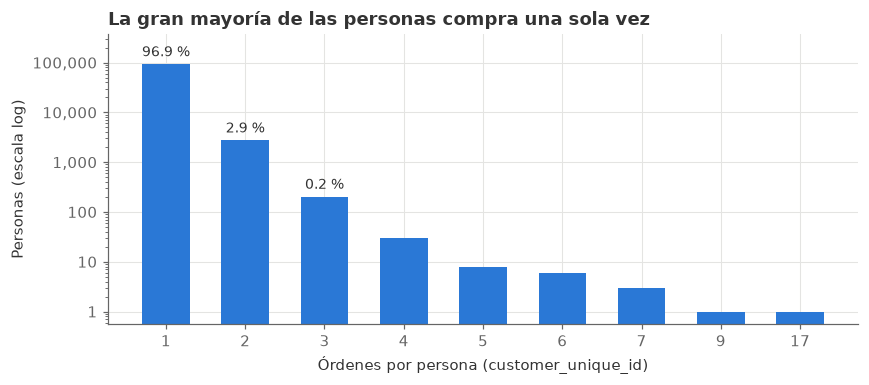

In [17]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(compras["ordenes_por_persona"].astype(str), compras["personas"], color=AZUL, width=0.6)
ax.set_yscale("log")
ax.set_ylim(top=compras["personas"].max() * 4)
ax.set_title("La gran mayoría de las personas compra una sola vez")
ax.set_xlabel("Órdenes por persona (customer_unique_id)")
ax.set_ylabel("Personas (escala log)")
formato_miles(ax)
for x, (n, pct) in enumerate(zip(compras["personas"], compras["pct_personas"])):
    if pct >= 0.2:
        ax.annotate(f"{pct:.1f} %", (x, n), ha="center", va="bottom", fontsize=9,
                    xytext=(0, 3), textcoords="offset points")
plt.tight_layout()
plt.show()

**Diferencia.** `customer_id` se crea **por orden**: hay tantos como órdenes (relación 1:1 con
`orders`). `customer_unique_id` identifica a la **persona**: unos 96 000 clientes reales, de los cuales
solo ~3 % compra más de una vez.

**Consecuencias**

- **Módulo A.** Cualquier variable de historial del cliente (por ejemplo, "¿ha sufrido retrasos
  antes?") debe calcularse por `customer_unique_id`. Por `customer_id` siempre valdría "primera compra".
  Aun así, como ~97 % compra una sola vez, esas variables estarán vacías casi siempre y aportan poco.
  Los históricos útiles serán los del **vendedor** y la **ruta**.
- **Módulo C** (no se desarrolla en este trabajo). La unidad de análisis es `customer_unique_id`, y
  la frecuencia del RFM es casi constante (1 compra), así que tendría que tratarse como binaria
  (recompra sí/no).

## 4. Cobertura temporal

In [18]:
por_mes = consulta("00_15_ordenes_por_mes")
display(por_mes)

,mes,ordenes,entregadas
0,2016-09-01,4,1.0
1,2016-10-01,324,265.0
2,2016-12-01,1,1.0
3,2017-01-01,800,750.0
4,2017-02-01,1780,1653.0
5,2017-03-01,2682,2546.0
6,2017-04-01,2404,2303.0
7,2017-05-01,3700,3546.0
8,2017-06-01,3245,3135.0
9,2017-07-01,4026,3872.0


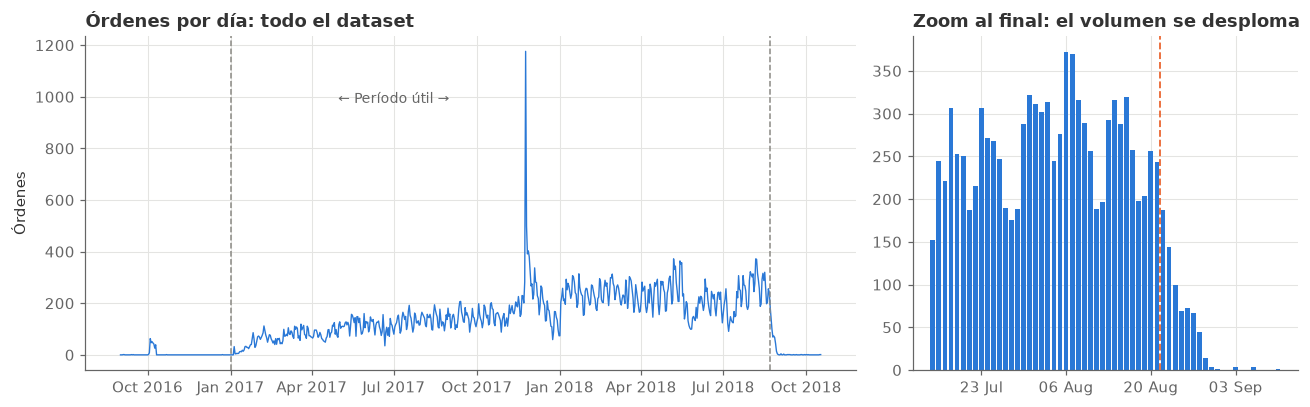

In [19]:
por_dia_total = consulta("00_16_ordenes_por_dia", list(RANGO_COMPLETO))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [2, 1]})

ax = axes[0]
ax.plot(por_dia_total["dia"], por_dia_total["ordenes"], color=AZUL, linewidth=0.9)
ax.axvline(pd.Timestamp(PERIODO_INICIO), color=GRIS, linestyle="--", linewidth=1)
ax.axvline(pd.Timestamp(PERIODO_FIN), color=GRIS, linestyle="--", linewidth=1)
ax.set_title("Órdenes por día: todo el dataset")
ax.set_ylabel("Órdenes")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.annotate("← Período útil →", (pd.Timestamp("2017-07-01"), 0.80), xycoords=("data", "axes fraction"),
            ha="center", color=TINTA_2, fontsize=9)

ax = axes[1]
zoom = por_dia_total[(por_dia_total["dia"] >= "2018-07-15") & (por_dia_total["dia"] <= "2018-09-10")]
ax.bar(zoom["dia"], zoom["ordenes"], color=AZUL, width=0.8)
ax.axvline(pd.Timestamp(PERIODO_FIN) - pd.Timedelta(hours=12), color=NARANJA, linestyle="--", linewidth=1.2)
ax.set_title("Zoom al final: el volumen se desploma")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=0, interval=2))
plt.tight_layout()
plt.show()

In [20]:
censura = consulta("00_17_estado_por_semana", ["2018-06-01"])
display(censura)

,semana,ordenes,pct_entregadas,pct_en_proceso,pct_canceladas
0,2018-05-28,518,99.23,0.58,0.19
1,2018-06-04,1438,98.89,0.76,0.35
2,2018-06-11,1514,98.88,0.99,0.13
3,2018-06-18,1457,99.04,0.55,0.41
4,2018-06-25,1401,98.64,0.79,0.57
5,2018-07-02,1196,98.49,0.84,0.67
6,2018-07-09,1001,97.10,1.60,1.30
7,2018-07-16,1678,98.27,1.01,0.72
8,2018-07-23,1646,97.81,1.46,0.73
9,2018-07-30,2058,97.28,1.36,1.36


**Decisión: período útil del 1 de enero de 2017 al 21 de agosto de 2018** (`PERIODO_FIN = 2018-08-22`, excluyente).

- **Inicio.** En 2016 hay 4 órdenes en septiembre, unas 320 en octubre concentradas en pocos días,
  **ninguna en noviembre** y 1 en diciembre. Es la etapa de arranque de la plataforma, con un hueco
  temporal. A partir de enero de 2017 la serie es continua.
- **Fin.** A partir del 22 de agosto de 2018 el volumen diario cae de forma sostenida (187, 144, 99… y
  1 orden el día 31), y en septiembre y octubre solo hay órdenes sueltas. No es una caída de la
  demanda: es el **corte de la extracción** del dataset.
- **Censura (clave para el Módulo A).** Las órdenes compradas cerca del final tuvieron menos tiempo para
  ser entregadas antes del corte. Las que todavía estaban en camino no aparecen como `delivered`, y es
  más probable que sean justamente las tardías. Por eso la partición de prueba del Módulo A termina el
  **15 de agosto**: más cerca del final, la tasa de retraso observada estaría sesgada hacia abajo.

➜ **Se implementa en** `00_22_ordenes_marcadas.sql` (marca `en_periodo_util`), que recibe
`PERIODO_INICIO` y `PERIODO_FIN` como parámetros `?` (sección 5.3).

## 5. De los hallazgos a los SQL de limpieza

Con el diagnóstico de las secciones 1 a 4 se escribieron **cuatro archivos de limpieza**. Cada uno
responde a hallazgos concretos:

| Hallazgo del diagnóstico | Evidencia | Decisión | Archivo que la implementa |
|---|---|---|---|
| Prefijos de 4 dígitos (se perdió el cero) | 2.5 | `lpad(prefijo, 5, '0')` | `00_20` y `00_22` |
| `geolocation` con ~53 filas por prefijo y 42 puntos fuera de Brasil | 1.2 y 2.6 | Filtrar la caja de Brasil y tomar la mediana por prefijo | `00_20` |
| Categoría nula / 2 categorías sin traducción | 2.7 | `sin_categoria` y traducción manual | `00_21` |
| Productos con peso = 0 g | 2.7 | Tratar como faltante | `00_21` |
| Meses de arranque y corte de extracción | 4 | Período útil 2017-01-01 a 2018-08-21 | `00_22` / `00_23` |
| Órdenes sin ítems | 2.3 | Excluir | `00_22` / `00_23` |
| Entrega antes que al transportador o que la aprobación | 2.2 | Excluir | `00_22` / `00_23` |
| `delivered` sin fecha de entrega o sin aprobación | 2.1 | Marcar; el Módulo A las excluye | `00_22` |
| Joins 1:N multiplican filas | 1.3 | Agregar por llave antes de unir | Todas las consultas |
| Pagos ≠ precio + flete | 2.4 | Valor de la orden desde `order_items` | Módulo A |
| `review_id` no es única | 1.1 | No se usan reseñas en A (son posteriores: fuga) | — |

Cada archivo crea una **tabla temporal** (vive en memoria y no modifica `olist.duckdb`). A continuación
se muestra cada consulta, se ejecuta y al final se verifica que la limpieza funcionó.

### 5.1 `00_20_geo_prefijo.sql` → tabla `geo_prefijo`

**Viene de** las secciones 1.2, 2.5 y 2.6: `geolocation` tiene muchas filas por prefijo, puntos fuera
de Brasil y prefijos que no cruzan con clientes y vendedores.

**Qué hace:** normaliza el prefijo a 5 dígitos, descarta los puntos fuera de Brasil y deja **una sola
fila por prefijo** con la mediana de latitud y longitud. Así, cruzar con esta tabla nunca multiplica
filas.

In [21]:
mostrar_sql("00_20_geo_prefijo")
ejecutar("00_20_geo_prefijo")

── sql/00_20_geo_prefijo.sql ────────────────────────────────────────
-- Módulo 0 · Tabla limpia: una coordenada por prefijo postal
-- Decisiones: (1) se descartan puntos fuera de la caja de Brasil, (2) se toma la MEDIANA
-- de latitud y longitud de cada prefijo (robusta a puntos atípicos), (3) el prefijo se
-- normaliza a 5 dígitos para que cruce con customers y sellers.
CREATE OR REPLACE TEMP TABLE geo_prefijo AS
SELECT
    lpad(geolocation_zip_code_prefix, 5, '0')  AS prefijo,
    median(geolocation_lat)                    AS lat,
    median(geolocation_lng)                    AS lng,
    count(*)                                   AS n_puntos
FROM geolocation
WHERE geolocation_lat BETWEEN -34 AND 5.5
  AND geolocation_lng BETWEEN -74 AND -34
GROUP BY prefijo;

✔ 00_20_geo_prefijo


### 5.2 `00_21_productos_limpios.sql` → tabla `productos_limpios`

**Viene de** la sección 2.7: productos sin categoría, categorías sin traducción y pesos imposibles.

**Qué hace:** una fila por producto, con la categoría limpia en portugués y en inglés, el peso (0 g
pasa a faltante), las dimensiones y el volumen del paquete, que el Módulo A usará como variable.

In [22]:
mostrar_sql("00_21_productos_limpios")
ejecutar("00_21_productos_limpios")

── sql/00_21_productos_limpios.sql ────────────────────────────────────────
-- Módulo 0 · Tabla limpia de productos
-- Decisiones: categoría nula → 'sin_categoria'; las 2 categorías sin traducción se traducen
-- a mano; peso 0 g se trata como faltante; se calcula el volumen del paquete en cm³.
CREATE OR REPLACE TEMP TABLE productos_limpios AS
SELECT
    p.product_id,
    coalesce(p.product_category_name, 'sin_categoria')                 AS categoria_pt,
    coalesce(
        t.product_category_name_english,
        CASE p.product_category_name
            WHEN 'pc_gamer' THEN 'pc_gamer'
            WHEN 'portateis_cozinha_e_preparadores_de_alimentos'
                 THEN 'portable_kitchen_and_food_preparers'
        END,
        'unknown'
    )                                                                  AS categoria_en,
    p.product_photos_qty                                               AS n_fotos,
    nullif(p.product_weight_g, 0)                                      AS peso_

### 5.3 `00_22_ordenes_marcadas.sql` y `00_23_ordenes_validas.sql` → tabla `ordenes_validas`

**Viene de** las secciones 2.1, 2.2, 2.3 y 4. La limpieza de órdenes se hace en dos pasos:

1. **`00_22` marca** cada orden con una columna verdadero/falso por cada regla de calidad, sin borrar
   nada. Así se puede contar cuántas órdenes elimina cada regla (embudo de abajo).

   | Marca | Regla | Sección |
   |---|---|---|
   | `en_periodo_util` | Comprada dentro del período útil (parámetros `?`) | 4 |
   | `tiene_items` | Tiene al menos un ítem | 2.3 |
   | `fechas_coherentes` | La entrega no es anterior al transportador ni a la aprobación | 2.2 |
   | `entregada` | Estado `delivered` con fecha de entrega (población del Módulo A) | 2.1 |
   | `tiene_aprobacion` | Tiene fecha de aprobación (momento de predicción del Módulo A) | 2.1 |

   También agrega del cliente el `customer_unique_id`, el estado y el prefijo ya corregido con `lpad`.

2. **`00_23` filtra** las órdenes que cumplen las tres primeras marcas. Ese es el resultado: `ordenes_validas`.

In [23]:
mostrar_sql("00_22_ordenes_marcadas")
ejecutar("00_22_ordenes_marcadas", [PERIODO_INICIO, PERIODO_FIN])

── sql/00_22_ordenes_marcadas.sql ────────────────────────────────────────
-- Módulo 0 · Todas las órdenes con las marcas de calidad que deciden si son válidas
-- Parámetros: ? = inicio del período útil (incluido), ? = fin del período útil (excluido)
CREATE OR REPLACE TEMP TABLE ordenes_marcadas AS
WITH periodo AS (
    SELECT ?::TIMESTAMP AS inicio, ?::TIMESTAMP AS fin
)
SELECT
    o.*,
    c.customer_unique_id,
    c.customer_state,
    lpad(c.customer_zip_code_prefix, 5, '0')                                  AS customer_prefijo,
    -- Marcas de calidad
    (o.order_purchase_timestamp >= p.inicio
     AND o.order_purchase_timestamp < p.fin)                                  AS en_periodo_util,
    EXISTS (SELECT 1 FROM order_items AS i WHERE i.order_id = o.order_id)     AS tiene_items,
    -- La entrega al cliente no puede ser anterior a la entrega al transportador ni a la
    -- aprobación (la aprobación es el momento en que se usa el modelo del Módulo A).
    (coalesce(o.order_deli

✔ 00_22_ordenes_marcadas


In [24]:
mostrar_sql("00_23_ordenes_validas")
ejecutar("00_23_ordenes_validas")

── sql/00_23_ordenes_validas.sql ────────────────────────────────────────
-- Módulo 0 · Órdenes válidas: base común para el resto del taller
-- Requiere haber ejecutado antes 00_22_ordenes_marcadas.sql
CREATE OR REPLACE TEMP TABLE ordenes_validas AS
SELECT *
FROM ordenes_marcadas
WHERE en_periodo_util
  AND tiene_items
  AND fechas_coherentes;

✔ 00_23_ordenes_validas


**Embudo de limpieza:** cuántas órdenes quedan después de aplicar cada regla.

In [25]:
embudo = consulta("00_24_embudo_limpieza")
embudo["pct_del_total"] = (100 * embudo["ordenes"] / embudo["ordenes"].iloc[0]).round(2)
display(embudo)

,paso,ordenes,pct_del_total
0,1. Órdenes en la base,99441,100.00
1,2. Compradas dentro del período útil,98390,98.94
2,3. … y con al menos un ítem,97669,98.22
3,4. … y con fechas coherentes → ordenes_validas,97589,98.14
4,5. … y entregadas con fecha de entrega (poblac...,95442,95.98
5,6. … y con fecha de aprobación,95428,95.96


Después de la limpieza se conserva cerca del **98 %** de las órdenes (`ordenes_validas`, paso 4). La
población del Módulo A (además entregadas, con fecha de entrega y de aprobación) queda en unas 95 400
órdenes, ~96 % de la base.

### 5.4 Verificación: ¿la limpieza corrigió lo que encontró el diagnóstico?

Cada problema detectado se vuelve a contar, ahora sobre las tablas limpias. **Todos deben dar 0.**

In [26]:
verificacion = consulta("00_26_verificacion_limpieza")
display(verificacion)
assert (verificacion["registros"] == 0).all(), "Alguna regla de limpieza no se cumplió."
print("✔ Todas las reglas de limpieza se cumplen.")

,tabla,chequeo,registros
0,geo_prefijo,Prefijos con menos de 5 dígitos,0
1,geo_prefijo,Prefijos repetidos (debe haber una fila por pr...,0
2,geo_prefijo,Coordenadas fuera de Brasil,0
3,productos_limpios,Productos sin categoría,0
4,productos_limpios,Categorías con nombre sin traducción,0
5,productos_limpios,Productos con peso = 0 g,0
6,ordenes_validas,Compradas fuera del período útil,0
7,ordenes_validas,Órdenes sin ítems,0
8,ordenes_validas,Entrega al cliente antes que al transportador,0
9,ordenes_validas,Entrega al cliente antes de la aprobación,0


✔ Todas las reglas de limpieza se cumplen.


In [27]:
cobertura_geo = consulta("00_25_cobertura_geo_limpia")
display(cobertura_geo)

,chequeo,total,con_coordenadas,pct_con_coordenadas
0,Órdenes válidas con coordenadas del cliente,97589,97315.0,99.72
1,Vendedores con coordenadas,3095,3087.0,99.74


Además, gracias a la corrección de prefijos, más del **99 %** de las órdenes válidas y de los vendedores
tiene coordenadas. Antes de la corrección, casi una cuarta parte de los clientes no las tenía (sección 2.5).

### 5.5 La información limpia que recibe el Módulo A

In [28]:
display(consulta("00_28_filas_tablas_limpias"))
display(consulta("00_27_tablas_limpias"))

,tabla,filas
0,geo_prefijo,19010
1,productos_limpios,32951
2,ordenes_validas,97589


,tabla,columnas,lista_columnas
0,geo_prefijo,4,"prefijo, lat, lng, n_puntos"
1,ordenes_validas,16,"order_id, customer_id, order_status, order_pur..."
2,productos_limpios,9,"product_id, categoria_pt, categoria_en, n_foto..."


Estas tres tablas son la **información limpia** del taller. El EDA de la sección 6 se hace sobre ellas,
y el Módulo A las recrea al iniciar ejecutando los mismos archivos `00_20` a `00_23` con los mismos
parámetros (sección 7).

## 6. EDA orientado al Módulo A

### 6.1 Tiempo de entrega y retraso

El target del Módulo A es **llegó tarde = fecha real de entrega > fecha estimada**, comparadas por
día calendario.

In [29]:
resumen_entrega = consulta("00_30_resumen_entrega")
display(resumen_entrega)

,medida,promedio,p05,p25,p50,p75,p95,maximo
0,Días de compra a entrega,12.5,3.0,7.0,10.0,16.0,29.0,210
1,Días prometidos (estimada − compra),24.4,11.0,19.0,24.0,29.0,39.0,156
2,Días de retraso (entrega − estimada),-11.8,-26.0,-17.0,-12.0,-7.0,3.0,188


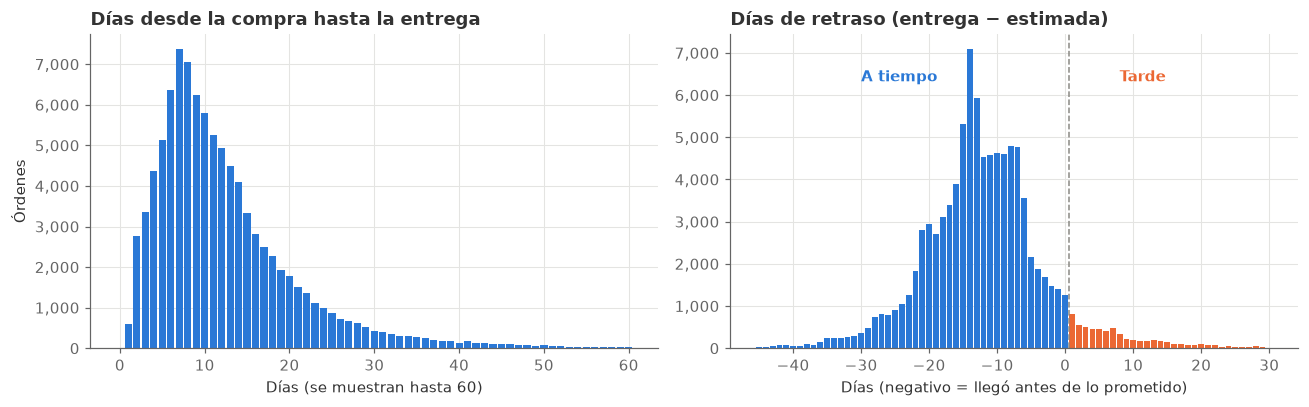

Órdenes tardías: 6,525 de 95,442 → 6.84 % (clase positiva)


In [30]:
distribucion = consulta("00_31_distribucion_entrega")
entrega = distribucion[(distribucion["medida"] == "dias_entrega") & (distribucion["dias"] <= 60)]
retraso = distribucion[(distribucion["medida"] == "dias_retraso") & (distribucion["dias"].between(-45, 30))]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))

ax = axes[0]
ax.bar(entrega["dias"], entrega["ordenes"], color=AZUL, width=0.85)
ax.set_title("Días desde la compra hasta la entrega")
ax.set_xlabel("Días (se muestran hasta 60)")
ax.set_ylabel("Órdenes")
formato_miles(ax)

ax = axes[1]
colores = [NARANJA if d > 0 else AZUL for d in retraso["dias"]]
ax.bar(retraso["dias"], retraso["ordenes"], color=colores, width=0.85)
ax.axvline(0.5, color=GRIS, linestyle="--", linewidth=1)
ax.set_title("Días de retraso (entrega − estimada)")
ax.set_xlabel("Días (negativo = llegó antes de lo prometido)")
formato_miles(ax)
ax.annotate("Tarde", (8, 0.85), xycoords=("data", "axes fraction"), color=NARANJA, fontweight="bold")
ax.annotate("A tiempo", (-30, 0.85), xycoords=("data", "axes fraction"), color=AZUL, fontweight="bold")
plt.tight_layout()
plt.show()

tarde = distribucion[(distribucion["medida"] == "dias_retraso") & (distribucion["dias"] > 0)]["ordenes"].sum()
total = distribucion[distribucion["medida"] == "dias_retraso"]["ordenes"].sum()
print(f"Órdenes tardías: {tarde:,} de {total:,} → {100 * tarde / total:.2f} % (clase positiva)")

**Lectura**

- La entrega típica tarda unos 10 días, con cola larga a la derecha.
- La fecha estimada es **conservadora**: la mediana de las órdenes llega unos 12 días *antes* de lo
  prometido. Por eso la clase positiva es pequeña (~7 %): el problema es **desbalanceado** y la
  *accuracy* no sirve como métrica.
- El plazo prometido (estimada − compra) se conoce en el momento de la aprobación. Es candidato natural
  a variable del Módulo A.

### 6.2 La tasa de retraso no es estable en el tiempo

In [31]:
mensual = consulta("00_32_retraso_mensual")
mensual["mes"] = pd.to_datetime(mensual["mes"])
display(mensual)

,mes,ordenes_entregadas,pct_tarde,dias_prometidos_prom,dias_entrega_prom
0,2017-01-01,749,2.94,40.1,12.7
1,2017-02-01,1650,2.97,32.5,13.3
2,2017-03-01,2545,4.56,25.4,13.0
3,2017-04-01,2303,6.56,28.0,15.0
4,2017-05-01,3544,2.99,24.9,11.4
5,2017-06-01,3133,3.03,24.7,12.0
6,2017-07-01,3861,2.80,24.0,11.5
7,2017-08-01,4191,2.91,24.1,11.0
8,2017-09-01,4142,4.39,23.1,11.7
9,2017-10-01,4478,4.18,23.7,11.7


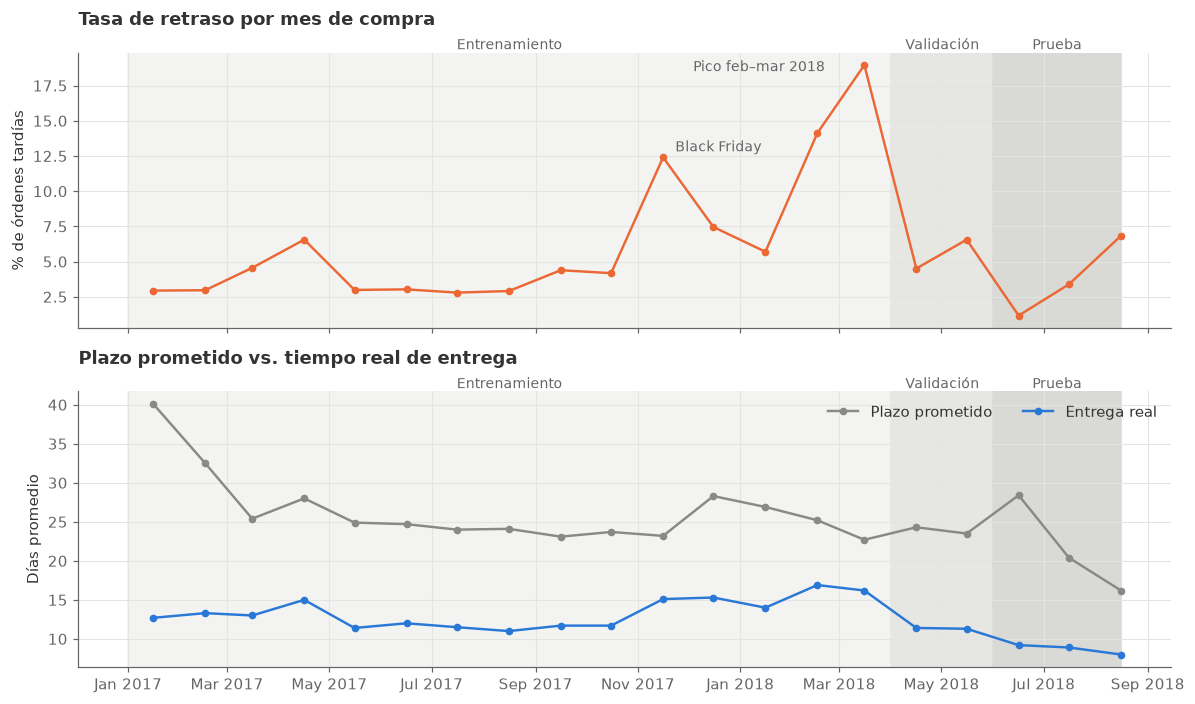

In [32]:
centro_mes = mensual["mes"] + pd.Timedelta(days=15)

fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)

ax = axes[0]
sombrear_particiones(ax)
ax.plot(centro_mes, mensual["pct_tarde"], color=NARANJA, marker="o", markersize=4)
ax.set_ylabel("% de órdenes tardías")
ax.set_title("Tasa de retraso por mes de compra", pad=18)
for fecha, etiqueta, desplazamiento in [("2017-11-01", "Black Friday", (8, 4)),
                                        ("2018-03-01", "Pico feb–mar 2018", (-112, -4))]:
    fila = mensual[mensual["mes"] == fecha].iloc[0]
    ax.annotate(etiqueta, (fila["mes"] + pd.Timedelta(days=15), fila["pct_tarde"]),
                xytext=desplazamiento, textcoords="offset points", fontsize=9, color=TINTA_2)

ax = axes[1]
sombrear_particiones(ax)
ax.plot(centro_mes, mensual["dias_prometidos_prom"], color=GRIS, marker="o", markersize=4, label="Plazo prometido")
ax.plot(centro_mes, mensual["dias_entrega_prom"], color=AZUL, marker="o", markersize=4, label="Entrega real")
ax.set_ylabel("Días promedio")
ax.set_title("Plazo prometido vs. tiempo real de entrega", pad=18)
ax.legend(loc="upper right", ncol=2)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.tight_layout()
plt.show()

In [33]:
particiones = consulta("00_33_retraso_por_particion", [INICIO_TRAIN, INICIO_VAL, INICIO_TEST, FIN_TEST])
display(particiones)

,particion,ordenes,ordenes_tarde,pct_tarde,dias_prometidos_prom,dias_entrega_prom
0,1. Entrenamiento,64022,5110.0,7.98,25.2,13.9
1,2. Validación,13532,749.0,5.54,23.9,11.4
2,3. Prueba,16437,627.0,3.81,22.3,8.9


**Lectura (deriva temporal)**

- La tasa de retraso **cae de una partición a la siguiente**: ~8 % en entrenamiento, ~5.5 % en
  validación y ~3.8 % en prueba.
- Dentro de entrenamiento hay picos fuertes: **noviembre de 2017** (Black Friday, volumen récord que
  saturó la logística) y **febrero–marzo de 2018** (casi 19 % en marzo).
- El segundo gráfico explica buena parte de la caída: el **tiempo real de entrega bajó** (de ~14 días
  en entrenamiento a ~9 en prueba) más rápido de lo que bajó el plazo prometido. El margen entre lo
  prometido y lo real creció.
- La relación también se ve al revés: en julio y agosto de 2018 Olist **acorta el plazo prometido**
  (de ~28 a ~16 días) y la tasa de retraso **vuelve a subir**. El plazo prometido es una variable clave.
- En validación (mayo de 2018) ocurrió el **paro nacional de camioneros en Brasil**, que afectó la
  logística. En prueba, además, actúa la **censura** descrita en la sección 4.

**Consecuencias para el Módulo A**

1. Un modelo entrenado con ~8 % de positivos verá ~4 % en prueba. Sus probabilidades tenderán a
   **sobreestimar** el riesgo, así que la **calibración** y el **umbral** deben revisarse con validación.
2. La PR-AUC depende de la prevalencia: un valor más bajo en prueba no implica por sí solo un peor
   modelo. Hay que compararla contra la prevalencia de cada partición (la PR-AUC de un modelo aleatorio).
3. El umbral elegido por costo en validación puede no ser óptimo en prueba. Esto se discute en el Módulo A.

### 6.3 Órdenes por día y por semana (demanda)

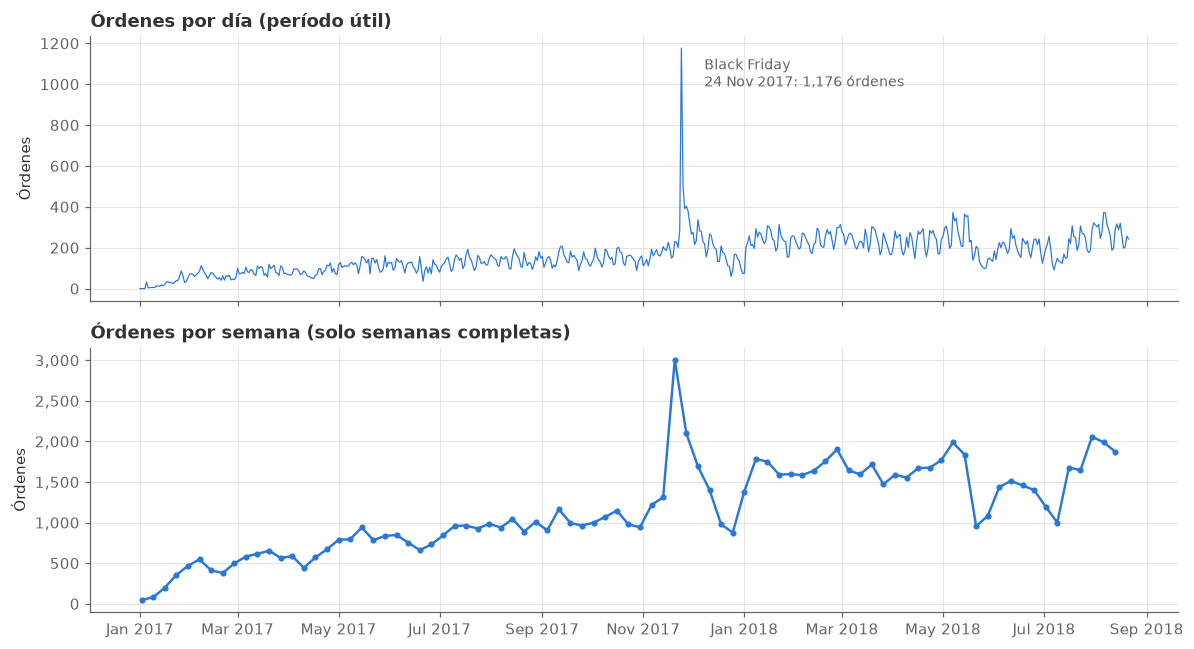

,num_dia,dia_semana,ordenes_promedio
0,1,Lunes,186.9
1,2,Martes,184.3
2,3,Miércoles,180.0
3,4,Jueves,171.2
4,5,Viernes,164.4
5,6,Sábado,126.8
6,7,Domingo,137.9


In [34]:
por_dia = consulta("00_16_ordenes_por_dia", [PERIODO_INICIO, PERIODO_FIN])
por_semana = consulta("00_37_ordenes_por_semana", [PERIODO_INICIO, PERIODO_FIN])

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)

ax = axes[0]
ax.plot(por_dia["dia"], por_dia["ordenes"], color=AZUL, linewidth=0.8)
pico = por_dia.loc[por_dia["ordenes"].idxmax()]
ax.annotate(f"Black Friday\n{pico['dia']:%d %b %Y}: {pico['ordenes']:,} órdenes",
            (pico["dia"], pico["ordenes"]), xytext=(15, -25), textcoords="offset points",
            fontsize=9, color=TINTA_2)
ax.set_title("Órdenes por día (período útil)")
ax.set_ylabel("Órdenes")

ax = axes[1]
ax.plot(por_semana["semana"], por_semana["ordenes"], color=AZUL, marker="o", markersize=3)
ax.set_title("Órdenes por semana (solo semanas completas)")
ax.set_ylabel("Órdenes")
formato_miles(ax)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.tight_layout()
plt.show()

dia_semana = consulta("00_38_ordenes_por_dia_semana", [PERIODO_INICIO, PERIODO_FIN])
display(dia_semana)

**Lectura.** La demanda crece durante 2017, tiene su pico en Black Friday (24 de noviembre de 2017) y
se estabiliza en 2018. Hay estacionalidad semanal: más compras al inicio de la semana y menos el fin de
semana. La caída de finales de mayo de 2018 coincide con el paro nacional de camioneros. Para el Módulo A esto sugiere variables de **calendario** (día de la semana, cercanía a Black
Friday) y de **carga del sistema**, porque los picos de volumen coinciden con los picos de retraso.

### 6.4 Distribución geográfica de clientes y vendedores

In [35]:
geografia = consulta("00_34_geografia_estados")
display(geografia)

,estado,ordenes_clientes,vendedores,pct_tarde
0,SP,40726,1849,4.55
1,RJ,12647,171,12.21
2,MG,11434,244,4.61
3,RS,5391,129,6.12
4,PR,4948,349,4.08
5,SC,3589,190,8.26
6,BA,3354,19,12.17
7,DF,2109,30,5.72
8,ES,2015,23,10.78
9,GO,1995,40,6.58


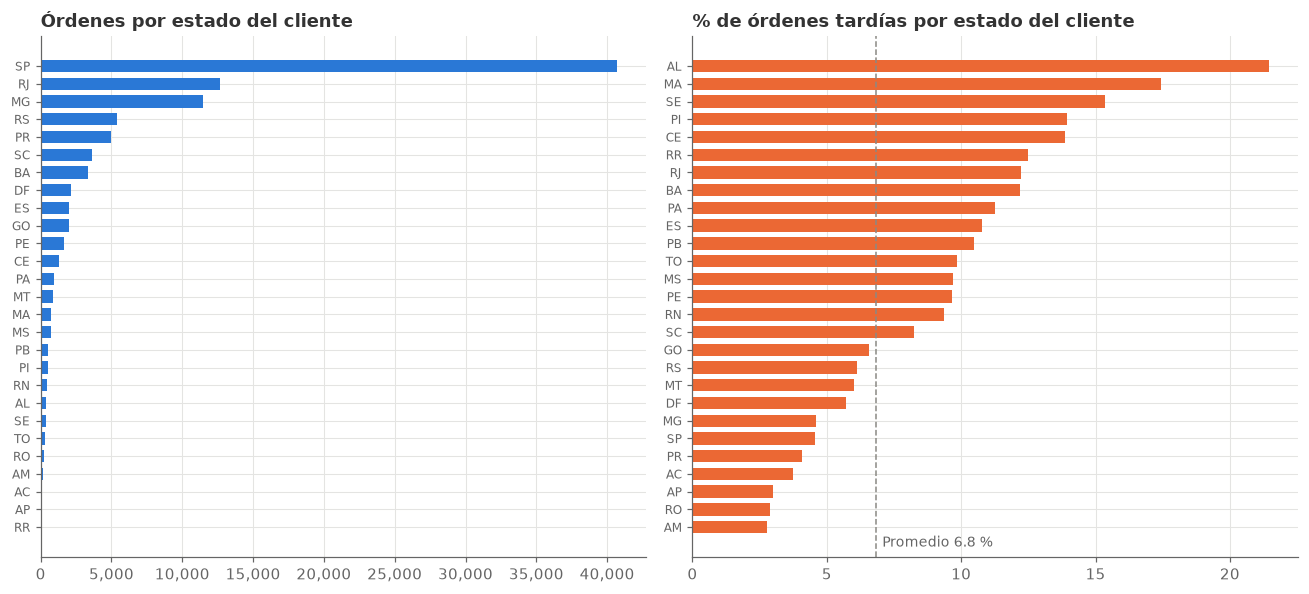

Vendedores por estado (top 6):


,estado,vendedores,pct
0,SP,1849,59.7
4,PR,349,11.3
2,MG,244,7.9
5,SC,190,6.1
1,RJ,171,5.5
3,RS,129,4.2


In [36]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))

ax = axes[0]
top = geografia.sort_values("ordenes_clientes")
ax.barh(top["estado"], top["ordenes_clientes"], color=AZUL, height=0.7, label="Órdenes de clientes")
ax.set_title("Órdenes por estado del cliente")
formato_miles(ax, eje="x")
ax.tick_params(axis="y", labelsize=8)

ax = axes[1]
tasa = geografia.dropna(subset=["pct_tarde"]).sort_values("pct_tarde")
ax.barh(tasa["estado"], tasa["pct_tarde"], color=NARANJA, height=0.7)
promedio = 100 * tarde / total
ax.axvline(promedio, color=GRIS, linestyle="--", linewidth=1)
ax.annotate(f"Promedio {promedio:.1f} %", (promedio, 0.02), xycoords=("data", "axes fraction"),
            xytext=(4, 0), textcoords="offset points", fontsize=9, color=TINTA_2)
ax.set_title("% de órdenes tardías por estado del cliente")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

vend = geografia[["estado", "vendedores"]].sort_values("vendedores", ascending=False)
vend["pct"] = (100 * vend["vendedores"] / vend["vendedores"].sum()).round(1)
print("Vendedores por estado (top 6):")
display(vend.head(6))

In [37]:
misma_uf = consulta("00_35_retraso_misma_uf")
display(misma_uf)

,ruta,ordenes_entregadas,pct_tarde,dias_entrega_prom
0,Vendedor en otro estado,61474,8.08,15.1
1,Vendedor y cliente en el mismo estado,33968,4.58,7.9


**Lectura**

- Clientes y vendedores se concentran en el **Sudeste**: São Paulo (SP) tiene ~42 % de las órdenes y
  ~60 % de los vendedores.
- El retraso es **muy heterogéneo por estado**: estados del Nordeste (AL, MA, SE, PI, CE, BA) están
  entre 12 % y 21 %, mientras SP, PR y MG están por debajo del 5 %. RJ es una excepción en el Sudeste (~12 %).
- Las órdenes que cruzan de estado se retrasan más y tardan más. **Estado de origen, estado de destino,
  si es la misma UF y la distancia** son variables candidatas para A, todas disponibles al aprobar.
- **Sesgo geográfico.** Los estados con pocas órdenes (RR, AP, AC) tienen tasas inestables. El modelo
  aprenderá sobre todo del Sudeste.

### 6.5 Tiempo entre la compra y la aprobación

In [38]:
aprobacion = consulta("00_36_tiempo_aprobacion")
display(aprobacion)

,ordenes,horas_p50,horas_p90,horas_p99,pct_aprobadas_mismo_dia
0,95428,0.35,34.52,89.16,69.36


La mitad de las órdenes se aprueba en menos de media hora, pero el 10 % tarda más de un día (por
ejemplo, pagos con boleto). Esto importa para el Módulo A: las variables **históricas** (tasa de
retraso previa del vendedor o de la ruta) deben contar solo órdenes **ya entregadas en el momento de
la aprobación** de la orden que se predice, no las compradas antes. Además, el medio de pago está
disponible al aprobar y puede capturar parte de esta demora.

## 7. Qué hereda el Módulo A

**Base.** El notebook `A_clasificacion` ejecuta al inicio, con los mismos parámetros:

```python
ejecutar("00_20_geo_prefijo")
ejecutar("00_21_productos_limpios")
ejecutar("00_22_ordenes_marcadas", [PERIODO_INICIO, PERIODO_FIN])
ejecutar("00_23_ordenes_validas")
```

**Población del Módulo A.** `ordenes_validas` con `entregada` y `tiene_aprobacion`. El target se
compara por día calendario.

**Hallazgos que guían el modelado**

1. **Desbalance.** ~7 % de órdenes tardías en total, cayendo de ~8 % (entrenamiento) a ~4 % (prueba).
   Se usarán PR-AUC, umbral por costo y calibración.
2. **Deriva temporal** fuerte (Black Friday, febrero–marzo de 2018, paro de mayo de 2018) y
   **censura** al final del período.
3. **Variables candidatas** disponibles al aprobar: plazo prometido, distancia y ruta entre estados,
   estado de origen y destino, peso y volumen, flete, categoría, medio de pago y cuotas, calendario,
   carga reciente de órdenes e históricos del vendedor y de la ruta (solo con órdenes ya entregadas).
4. **Prohibidas por fuga:** fecha de entrega al transportador, fecha real de entrega, reseñas y
   cualquier histórico calculado con órdenes no entregadas a la fecha de aprobación.

In [39]:
con.close()
print("Conexión cerrada.")

Conexión cerrada.
